# Zimbabwe Healthcare Accessibility Explorer
## Notebook 2 — Spatial Cleaning and Preparation
**Author: Tinashe Clifford Makandise**

### Purpose
Prepare traceable facility locations, reporting boundaries and population-cell centres for subsequent exploratory and accessibility analysis. Preserve raw inputs, report exclusions and reconcile population totals. This notebook does not calculate accessibility distances or recommend facility locations.

Run the updated Notebook 1 first. Save this notebook beside it in `notebooks/` within the extracted project. Use the same environment from `requirements-dev.txt`. Required source files are already in the updated Stage 1 package. All work is local; no downloads are required. Processing population cells may take a few minutes depending on your computer.

Historical facility data and 2020 modelled population remain an exploratory mixed-period combination. Public-sector here includes government/local-authority and some not-for-profit providers, not all providers. Straight-line accessibility is deferred to Notebook 4.

In [1]:
from pathlib import Path
import json, hashlib, re, unicodedata, platform
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from rasterio.transform import xy
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED = ROOT / "data/raw", ROOT / "data/processed"
REPORTS, TABLES, MAPS = ROOT / "reports", ROOT / "outputs/tables", ROOT / "outputs/maps"
for folder in [PROCESSED, REPORTS, TABLES, MAPS]:
    folder.mkdir(parents=True, exist_ok=True)
quality1 = json.loads((REPORTS / "01_data_quality_report.json").read_text(encoding="utf-8"))
required_files = ["ssa_public_health_facilities_2019.xlsx", "zwe_ppp_2020_1km_Aggregated_UNadj.tif",
                  "zwe_admin0.geojson", "zwe_admin1.geojson", "zwe_admin2.geojson"]
input_hashes = {}
for name in required_files:
    path = RAW / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing source: {path}. Extract the updated Stage 1 package.")
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == quality1["source_files"][name]["sha256"], f"Source changed: {name}. Rerun Notebook 1 and review."
    input_hashes[name] = digest
print("Verified five required input files against Notebook 1 fingerprints.")

Verified five required input files against Notebook 1 fingerprints.


### 1. Standardise the Zimbabwe facility records
Keep original fields alongside cleaned labels. Unicode NFKC and whitespace normalisation resolve nonbreaking spaces in province labels without changing the original source text. Coordinates are converted numerically; no missing location is imputed.

A stable ID uses the original Excel row number, allowing every record to be traced back to the supplied workbook. Exact canonical duplicates can be removed deterministically while logging the removed IDs. Same-name or same-coordinate records alone are insufficient evidence of duplication.

In [2]:
def clean_label(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value))).strip()

raw_facilities = pd.read_excel(RAW / "ssa_public_health_facilities_2019.xlsx", sheet_name="SSA MFL")
country = raw_facilities["Country"].map(clean_label).str.casefold()
fac = raw_facilities.loc[country.eq("zimbabwe")].copy()
fac.insert(0, "source_excel_row", fac.index + 2)
fac["facility_id"] = fac.source_excel_row.map(lambda row: f"ZWE_MFL_{row:06d}")
fac = fac.rename(columns={"Admin1": "source_province", "Facility name": "source_name",
                          "Facility type": "source_type", "Ownership": "source_ownership"})
for target, source in [("province_clean", "source_province"), ("facility_name", "source_name"),
                       ("facility_type", "source_type"), ("ownership", "source_ownership")]:
    fac[target] = fac[source].map(clean_label)
fac["latitude"] = pd.to_numeric(fac["Lat"], errors="coerce")
fac["longitude"] = pd.to_numeric(fac["Long"], errors="coerce")
fac["coordinate_valid"] = (np.isfinite(fac.latitude) & np.isfinite(fac.longitude)
                           & fac.latitude.between(-90, 90) & fac.longitude.between(-180, 180))
canonical = ["province_clean", "facility_name", "facility_type", "ownership", "latitude", "longitude"]
fac["canonical_duplicate"] = fac.duplicated(canonical, keep="first")
fac["status"] = np.select([~fac.coordinate_valid, fac.canonical_duplicate],
                           ["missing_or_invalid_coordinates", "canonical_duplicate"], default="candidate")
print("Original province labels:", fac.source_province.nunique())
print("Normalised province labels:", fac.province_clean.nunique())
print(fac.status.value_counts().to_string())
print("Whitespace-normalised province records:", int(fac.source_province.ne(fac.province_clean).sum()))
assert fac.facility_id.is_unique

Original province labels: 14
Normalised province labels: 10
status
candidate                         1201
missing_or_invalid_coordinates      35
Whitespace-normalised province records: 24


### 2. Prepare polygon reporting layers
Use only the national, province and district polygon layers. Reference lines/points and wards are not needed for this stage. Require valid, nonempty polygon geometries and unique nonmissing codes; unexpected failures stop processing rather than trigger silent repairs.

District codes are the join keys. Names are retained for display. EPSG:4326 stores geographic coordinates; EPSG:6933 is used below for equal-area diagnostics only, not kilometre-distance calculations.

In [3]:
country_boundary = gpd.read_file(RAW / "zwe_admin0.geojson")
provinces = gpd.read_file(RAW / "zwe_admin1.geojson")
districts = gpd.read_file(RAW / "zwe_admin2.geojson")
for layer, code_col in [(country_boundary, "adm0_pcode"), (provinces, "adm1_pcode"), (districts, "adm2_pcode")]:
    assert layer.crs is not None
    assert layer.geometry.notna().all() and (~layer.is_empty).all() and layer.is_valid.all()
    assert layer.geom_type.isin(["Polygon", "MultiPolygon"]).all()
    assert layer[code_col].notna().all() and layer[code_col].is_unique
country_boundary = country_boundary.to_crs(4326)[["adm0_name", "adm0_pcode", "geometry"]].copy()
provinces = provinces.to_crs(4326)[["adm1_name", "adm1_pcode", "adm0_pcode", "geometry"]].copy()
districts = districts.to_crs(4326)[["adm2_name", "adm2_pcode", "adm1_name", "adm1_pcode", "geometry"]].copy()
assert set(districts.adm1_pcode).issubset(set(provinces.adm1_pcode))
assert len(country_boundary) == 1 and country_boundary.adm0_pcode.iloc[0] == "ZW"
print(f"Prepared {len(country_boundary)} country, {len(provinces)} province and {len(districts)} district polygons.")

Prepared 1 country, 10 province and 91 district polygons.


### 3. Check boundary coverage, overlap and hierarchy
Compare the country polygon with the union of district polygons in an equal-area CRS. Check overlapping district interiors and district containment in their coded parent provinces. Shared borders have zero area and are allowed.

Numerical slivers can arise during projection and geometry operations. A predeclared diagnostic tolerance of 0.01 square kilometres per pair/district and a 0.01% country-area discrepancy is used here. Report the exact measurements; these tolerances are computational screening choices, not a claim of legal boundary accuracy. Meaningful failures require review before population aggregation.

In [4]:
area_crs = "EPSG:6933"
d_area = districts.to_crs(area_crs)
p_area = provinces.to_crs(area_crs).set_index("adm1_pcode")
c_area = country_boundary.to_crs(area_crs).geometry.iloc[0]
d_union = d_area.geometry.union_all()
overlap_pairs = []
for i, geom in enumerate(d_area.geometry):
    for j in d_area.sindex.query(geom, predicate="intersects"):
        j = int(j)
        if j <= i:
            continue
        area_km2 = geom.intersection(d_area.geometry.iloc[j]).area / 1e6
        if area_km2 > 0:
            overlap_pairs.append({"district_a": districts.adm2_pcode.iloc[i],
                                  "district_b": districts.adm2_pcode.iloc[j], "overlap_km2": area_km2})
parent_spill = [geom.difference(p_area.loc[row.adm1_pcode, "geometry"]).area / 1e6
                for geom, (_, row) in zip(d_area.geometry, d_area.iterrows())]
country_area = c_area.area / 1e6
boundary_diagnostics = {
    "country_area_km2": country_area,
    "country_not_covered_by_districts_km2": c_area.difference(d_union).area / 1e6,
    "district_union_outside_country_km2": d_union.difference(c_area).area / 1e6,
    "district_sum_minus_union_km2": (d_area.area.sum() - d_union.area) / 1e6,
    "max_pair_overlap_km2": max([p["overlap_km2"] for p in overlap_pairs], default=0.0),
    "max_district_outside_parent_km2": max(parent_spill, default=0.0),
}
print(json.dumps(boundary_diagnostics, indent=2))
assert boundary_diagnostics["max_pair_overlap_km2"] < .01
assert boundary_diagnostics["max_district_outside_parent_km2"] < .01
assert (boundary_diagnostics["country_not_covered_by_districts_km2"] + boundary_diagnostics["district_union_outside_country_km2"]) / country_area < .0001
pd.DataFrame(overlap_pairs, columns=["district_a", "district_b", "overlap_km2"]).to_csv(TABLES / "02_boundary_overlap_audit.csv", index=False)

{
  "country_area_km2": 390772.2900033928,
  "country_not_covered_by_districts_km2": 0.0,
  "district_union_outside_country_km2": 0.0,
  "district_sum_minus_union_km2": 1.03759765625e-09,
  "max_pair_overlap_km2": 0.0,
  "max_district_outside_parent_km2": 0.0
}


### 4. Assign facilities to districts without moving coordinates
Use point–polygon intersection so points on borders are considered. Retain one unambiguous district assignment; if a point intersects multiple districts, choose the lexicographically smallest code for reproducible reporting and flag it for review. This convention is not evidence of a facility's administrative affiliation.

Do not snap unmatched points to the nearest district. Keep separate statuses for outside-country and country-inside-but-unmatched records. Preserve source province labels and flag disagreement with the spatial province. Valid in-country facilities can remain eligible for later nearest-facility analysis even if a reporting assignment needs review.

In [5]:
candidate = fac[fac.status.eq("candidate")].copy()
points = gpd.GeoDataFrame(candidate, geometry=gpd.points_from_xy(candidate.longitude, candidate.latitude), crs=4326)
national_geometry = country_boundary.geometry.iloc[0]
points["inside_country"] = points.geometry.intersects(national_geometry)
joined = gpd.sjoin(points, districts, how="left", predicate="intersects")
match_counts = joined.groupby("facility_id").adm2_pcode.count()
chosen = joined.sort_values(["facility_id", "adm2_pcode"], na_position="last").drop_duplicates("facility_id").copy()
chosen["district_match_count"] = chosen.facility_id.map(match_counts).astype(int)
chosen["multiple_district_matches"] = chosen.district_match_count.gt(1)
chosen["province_disagreement"] = chosen.province_clean.str.casefold().ne(chosen.adm1_name.fillna("").map(clean_label).str.casefold()) & chosen.adm2_pcode.notna()
chosen["status"] = np.select([~chosen.inside_country, chosen.adm2_pcode.isna()],
                              ["outside_country", "unmatched_district"], default="accepted")
locations = chosen.loc[chosen.inside_country].drop(columns="index_right").copy()
assert locations.facility_id.is_unique
status_map = chosen.set_index("facility_id").status
fac.loc[fac.facility_id.isin(status_map.index), "status"] = fac.facility_id.map(status_map)
facility_audit = {
    "original_rows": len(fac), "usable_in_country_locations": len(locations),
    "status_counts": {str(k): int(v) for k,v in fac.status.value_counts().items()},
    "multiple_district_assignments": int(chosen.multiple_district_matches.sum()),
    "province_disagreements": int(chosen.province_disagreement.sum()),
}
print(json.dumps(facility_audit, indent=2))
assert sum(facility_audit["status_counts"].values()) == len(fac)
chosen.loc[chosen.province_disagreement].drop(columns="geometry").to_csv(TABLES / "02_facility_province_disagreements.csv", index=False)
chosen.loc[chosen.multiple_district_matches].drop(columns="geometry").to_csv(TABLES / "02_facility_border_assignments.csv", index=False)

{
  "original_rows": 1236,
  "usable_in_country_locations": 1201,
  "status_counts": {
    "accepted": 1201,
    "missing_or_invalid_coordinates": 35
  },
  "multiple_district_assignments": 0,
  "province_disagreements": 2
}


### 5. Convert positive population cells to their native grid centres
Preserve each cell's original count and assign a stable ID from raster row/column. Do not resample, divide by area or round population counts. NoData cells are excluded; valid zero-population cells contribute no population and are counted separately.

Assign each cell's entire population to its centre for this first analysis. This can exclude cells straddling the national boundary if their centres fall outside, or assign border populations to one side. We quantify the population affected; later sensitivity checks must consider this approximation. Polygon-overlap allocation would be a different method and should not be silently mixed with centre allocation.

In [6]:
with rasterio.open(RAW / "zwe_ppp_2020_1km_Aggregated_UNadj.tif") as src:
    array = src.read(1, masked=True)
    valid = ~np.ma.getmaskarray(array)
    values = array.filled(0).astype("float64")
    assert np.isfinite(values[valid]).all() and (values[valid] >= 0).all()
    positive = valid & (values > 0)
    rows, cols = np.nonzero(positive)
    xs, ys = xy(src.transform, rows, cols, offset="center")
    cells = gpd.GeoDataFrame({"cell_id": rows.astype("int64") * src.width + cols,
                              "raster_row": rows, "raster_col": cols, "population": values[rows, cols]},
                             geometry=gpd.points_from_xy(xs, ys), crs=src.crs).to_crs(4326)
    raster_population = float(values[valid].sum())
    zero_cells = int((valid & (values == 0)).sum())
    nodata_cells = int((~valid).sum())
cells["longitude"] = cells.geometry.x
cells["latitude"] = cells.geometry.y
shapely.prepare(national_geometry)
cells["inside_country"] = shapely.intersects_xy(national_geometry, cells.longitude.to_numpy(), cells.latitude.to_numpy())
assert cells.cell_id.is_unique
print("Positive cells:", len(cells), "Zero-population cells:", zero_cells, "NoData cells:", nodata_cells)
print(f"Original valid-cell population sum: {raster_population:,.3f}")

Positive cells: 479646 Zero-population cells: 0 NoData cells: 286700
Original valid-cell population sum: 14,862,927.001


### 6. Assign cells to districts and reconcile population
Assign interior centres with a within join, then intersect unresolved border centres with district polygons, choosing the lowest code for any border tie and recording its magnitude. Keep in-country centres unmatched to districts in a separate audit; do not drop them unnoticed. Do not allocate population to administrative reference points.

We reconcile the original raster total into three mutually exclusive components: outside-country centres, in-country unmatched centres, and in-country assigned centres. The assigned table is the basis for district summaries. The exported in-country table retains unmatched cells so later national calculations can account for them.

In [7]:
in_country = cells.loc[cells.inside_country].copy()
district_join_columns = ["adm2_pcode", "adm2_name", "adm1_pcode", "adm1_name", "geometry"]
# Within uses the efficient polygon-to-point query; intersect only unresolved border centres.
cell_join = gpd.sjoin(in_country, districts[district_join_columns], how="left", predicate="within")
unresolved_ids = cell_join.loc[cell_join.adm2_pcode.isna(), "cell_id"]
if len(unresolved_ids):
    border_join = gpd.sjoin(in_country[in_country.cell_id.isin(unresolved_ids)], districts[district_join_columns], how="left", predicate="intersects")
    cell_join = pd.concat([cell_join[~cell_join.cell_id.isin(unresolved_ids)], border_join])
cell_counts = cell_join.groupby("cell_id").adm2_pcode.count()
prepared_cells = cell_join.sort_values(["cell_id", "adm2_pcode"], na_position="last").drop_duplicates("cell_id").copy()
prepared_cells["district_match_count"] = prepared_cells.cell_id.map(cell_counts).astype(int)
prepared_cells["multiple_district_matches"] = prepared_cells.district_match_count.gt(1)
prepared_cells = prepared_cells.drop(columns="index_right")
assigned = prepared_cells.adm2_pcode.notna()
outside_population = float(cells.loc[~cells.inside_country, "population"].sum())
unmatched_population = float(prepared_cells.loc[~assigned, "population"].sum())
assigned_population = float(prepared_cells.loc[assigned, "population"].sum())
reconciled = outside_population + unmatched_population + assigned_population
population_audit = {
    "original_raster_population": raster_population, "positive_cells": len(cells),
    "zero_population_cells": zero_cells, "nodata_cells": nodata_cells,
    "outside_country_centre_cells": int((~cells.inside_country).sum()),
    "outside_country_centre_population": outside_population,
    "inside_country_unmatched_cells": int((~assigned).sum()),
    "inside_country_unmatched_population": unmatched_population,
    "assigned_population": assigned_population,
    "inside_country_population": float(prepared_cells.population.sum()),
    "multiple_district_cells": int(prepared_cells.multiple_district_matches.sum()),
    "multiple_district_cell_population": float(prepared_cells.loc[prepared_cells.multiple_district_matches, "population"].sum()),
    "reconciliation_difference": raster_population - reconciled,
    "outside_country_population_percent": outside_population / raster_population * 100,
}
np.testing.assert_allclose(reconciled, raster_population, rtol=1e-10, atol=1e-5)
assert prepared_cells.cell_id.is_unique and len(prepared_cells) == len(in_country)
print(json.dumps(population_audit, indent=2))
cell_export_columns = ["cell_id", "raster_row", "raster_col", "population", "longitude", "latitude", "adm2_pcode", "adm2_name", "adm1_pcode", "adm1_name", "district_match_count", "multiple_district_matches"]
prepared_cells.loc[~assigned, cell_export_columns].to_csv(TABLES / "02_population_unmatched_district.csv", index=False)
cells.loc[~cells.inside_country].drop(columns="geometry").to_csv(TABLES / "02_population_outside_country_centres.csv", index=False)

{
  "original_raster_population": 14862927.0006076,
  "positive_cells": 479646,
  "zero_population_cells": 0,
  "nodata_cells": 286700,
  "outside_country_centre_cells": 615,
  "outside_country_centre_population": 11082.865601629019,
  "inside_country_unmatched_cells": 0,
  "inside_country_unmatched_population": 0.0,
  "assigned_population": 14851844.135005971,
  "inside_country_population": 14851844.135005971,
  "multiple_district_cells": 0,
  "multiple_district_cell_population": 0.0,
  "reconciliation_difference": 0.0,
  "outside_country_population_percent": 0.07456718048319788
}


### 7. Inspect a preparation map
Show accepted in-country facility locations against district boundaries. A successful spatial join does not verify the original coordinates on the ground. Source-province disagreements remain explicitly flagged, and all 35 missing-coordinate records are preserved in the facility audit rather than placed at invented locations.

This map shows prepared inputs, not measured accessibility.


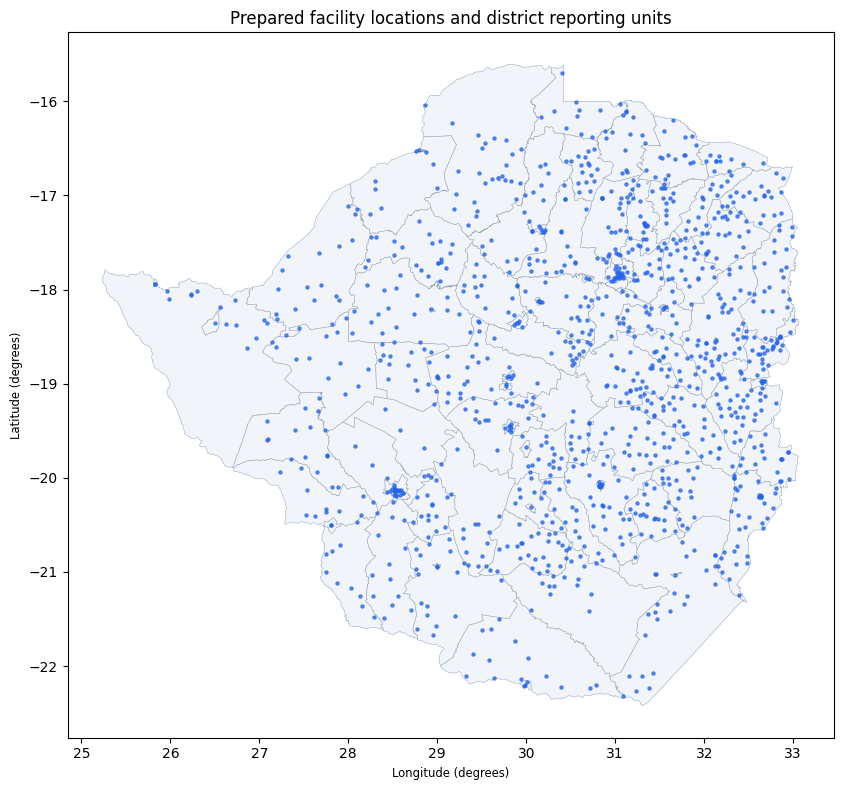

In [8]:
fig, ax = plt.subplots(figsize=(9, 8))
districts.plot(ax=ax, facecolor="#f1f5f9", edgecolor="#94a3b8", linewidth=.35)
locations.plot(ax=ax, color="#2563eb", markersize=5, alpha=.7)
ax.set(title="Prepared facility locations and district reporting units", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
plt.tight_layout()
plt.savefig(MAPS / "02_prepared_facilities_and_districts.png", dpi=150, bbox_inches="tight")
plt.show()
print("This map shows prepared inputs, not measured accessibility.")

### 8. Export prepared inputs and a processing record
Write the facility locations and polygon layers as GeoJSON, population centres as CSV, and detailed audits as tables/JSON. Population CSV is used for portability; later notebooks can reconstruct point geometry from its latitude/longitude fields. No additional population rounding or raster resampling is performed.

Only prepared data are written. Raw source checksums must remain unchanged. Retain these outputs alongside Notebook 1 sources so Notebook 3 can run without repeating preparation.

In [9]:
location_columns = ["facility_id", "source_excel_row", "facility_name", "facility_type", "ownership", "source_province", "province_clean", "latitude", "longitude", "adm2_pcode", "adm2_name", "adm1_pcode", "adm1_name", "district_match_count", "multiple_district_matches", "province_disagreement", "status", "geometry"]
locations[location_columns].to_file(PROCESSED / "facilities_prepared.geojson", driver="GeoJSON")
country_boundary.to_file(PROCESSED / "country_prepared.geojson", driver="GeoJSON")
provinces.to_file(PROCESSED / "provinces_prepared.geojson", driver="GeoJSON")
districts.to_file(PROCESSED / "districts_prepared.geojson", driver="GeoJSON")
prepared_cells[cell_export_columns].to_csv(PROCESSED / "population_cells_prepared.csv", index=False)
fac.to_csv(TABLES / "02_all_facility_records_audit.csv", index=False)
fac.loc[~fac.status.eq("accepted")].to_csv(TABLES / "02_facility_records_for_review.csv", index=False)
district_population = prepared_cells.loc[assigned].groupby("adm2_pcode").population.sum()
district_population.reindex(districts.adm2_pcode, fill_value=0).rename("population").to_csv(TABLES / "02_district_population_preparation_totals.csv")
np.testing.assert_allclose(district_population.sum(), assigned_population, rtol=1e-10, atol=1e-5)
# Confirm exported numeric population totals survive a CSV round trip.
restored_cells = pd.read_csv(PROCESSED / "population_cells_prepared.csv", usecols=["cell_id", "population"])
assert restored_cells.cell_id.is_unique and len(restored_cells) == len(prepared_cells)
np.testing.assert_allclose(restored_cells.population.sum(), prepared_cells.population.sum(), rtol=1e-10, atol=1e-5)
output_files = [PROCESSED / name for name in ["facilities_prepared.geojson", "country_prepared.geojson", "provinces_prepared.geojson", "districts_prepared.geojson", "population_cells_prepared.csv"]]
record = {"author": "Tinashe Clifford Makandise", "facility_audit": facility_audit,
          "boundary_diagnostics": boundary_diagnostics, "population_audit": population_audit,
          "methods": {"population_assignment": "positive native raster-cell centre; full count assigned to centre",
                      "district_border_tie": "lowest district code; flag retained",
                      "unmatched": "no snapping; retain audit and account separately",
                      "facility_missing_coordinates": "excluded from mapped analytical locations; source records retained",
                      "area_diagnostics_crs": area_crs, "distance_analysis": "not yet performed"},
          "input_sha256": input_hashes,
          "output_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in output_files},
          "versions": {"python": platform.python_version(), "geopandas": gpd.__version__, "pandas": pd.__version__, "numpy": np.__version__, "rasterio": rasterio.__version__}}
(REPORTS / "02_preparation_report.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
for name, digest in input_hashes.items():
    assert hashlib.sha256((RAW / name).read_bytes()).hexdigest() == digest
print("Five prepared datasets, review tables and a processing report saved. Raw inputs unchanged.")
print("Next: Notebook 3 — Exploratory Spatial Analysis.")

Five prepared datasets, review tables and a processing report saved. Raw inputs unchanged.
Next: Notebook 3 — Exploratory Spatial Analysis.


### Interpretation and review
We now have traceable facility locations, consistent reporting polygons and population-cell centres. In-country and assigned totals may differ from the original raster total because boundaries and grid extents differ. These differences are quantified, not silently redistributed.

Before interpreting district counts, inspect the facility province disagreement report. Spatial classification and source administrative affiliation need not agree. Facility counts and population denominators use different reference periods and do not prove current service availability.

**Next: Notebook 3.** Explore facility types, district counts, population distribution and facilities per population. Accessibility distances remain for Notebook 4.

Review questions: Why retain missing-coordinate records? Why use codes rather than names as join keys? Why does a cell-centre boundary rule change population totals? Why is EPSG:4326 unsuitable for directly interpreting geometry distances as kilometres?